In [4]:
import os
os.chdir("..")

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# from src.data import load_data

In [6]:
# df=  load_data()
df = pd.read_csv("data/raw/telco_churn.csv")

In [ ]:
# Informations globales sur le dataset

print(df.shape) # nombre de lignes et de colonnes
df.info()       # types et valeurs manquantes


(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [8]:
print(df.describe())   # stats sur les colonnes numériques
print(df.nunique().sort_values) # cardinalité de chaque colonne

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000
<bound method Series.sort_values of customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn         

In [9]:
# TotalCharges est object alors qu'elle devrait être numérique

print(df["TotalCharges"].dtype)
mask = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print(df.loc[mask, ["tenure", "MonthlyCharges", "TotalCharges"]]) # 11 clients avec tenure=0: ils n'ont encore rien payé

str
      tenure  MonthlyCharges TotalCharges
488        0           52.55             
753        0           20.25             
936        0           80.85             
1082       0           25.75             
1340       0           56.05             
3331       0           19.85             
3826       0           25.35             
4380       0           20.00             
5218       0           19.70             
6670       0           73.35             
6754       0           61.90             


Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


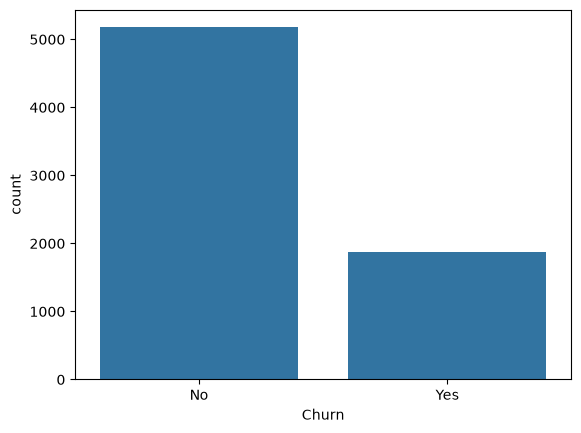

In [10]:
## Déséquilibre de la cible

print(df["Churn"].value_counts(normalize=True))  # environ 73% / 27%
sns.countplot(data=df, x="Churn")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_5860\1171502037.py:7: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\HP\Desktop\DataForge\Prediction_Churn\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


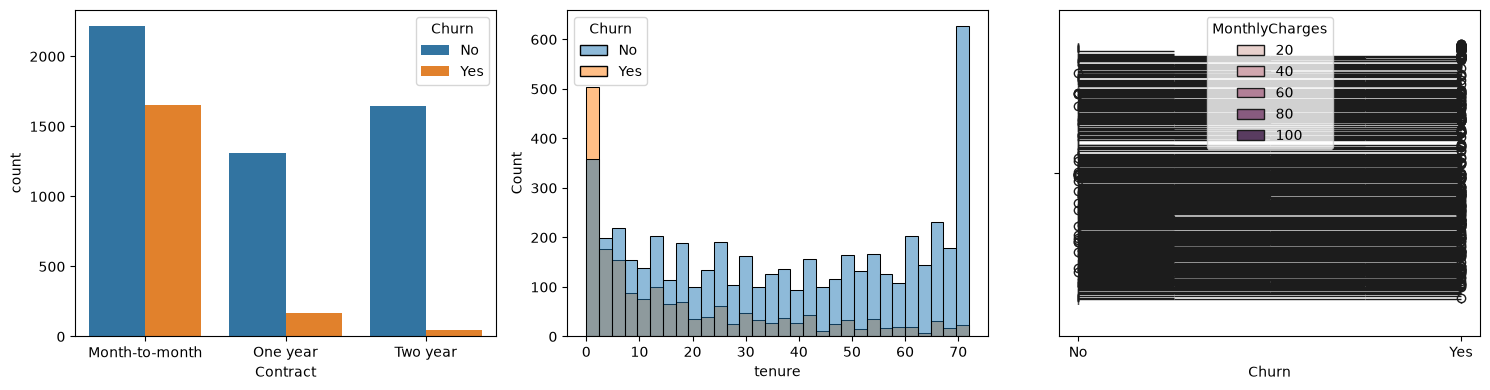

In [12]:
## Churn selon quelques variables clés

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
sns.histplot(data=df, x="tenure", hue="Churn",bins=30, ax=axes[1])
sns.boxplot(data=df, x="Churn", hue="MonthlyCharges", ax=axes[2])
plt.tight_layout()
plt.show()

In [14]:
## Taux de churn par modalité 
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(df.groupby(col)["Churn"].apply(lambda s:(s=="Yes").mean()).round(3), "\n")

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64 

InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64 

PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Electronic check             0.453
Mailed check                 0.191
Name: Churn, dtype: float64 

